In [ ]:
!pip install librosa scikit-learn soundfile matplotlib numpy scipy tqdm SpeechRecognition pydub ffmpeg-python --quiet


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 32.9/32.9 MB 56.8 MB/s eta 0:00:00


**Mount Google Drive**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


**Data Set Path & Discovery**

In [ ]:
import os, glob

dataset_path = "/content/drive/MyDrive/VoiceDataset"   # <- EDIT if needed

if not os.path.exists(dataset_path):
    raise FileNotFoundError(f"Dataset path not found: {dataset_path}")

# Expected dataset structure: many session subfolders each containing euphoric.wav, joyfully.wav, sad.wav, surprised.wav (or other extensions)
emotion_classes = ["euphoric", "joyfully", "sad", "surprised"]

raw_files = []
for sub in sorted(os.listdir(dataset_path)):
    subp = os.path.join(dataset_path, sub)
    if os.path.isdir(subp):
        for emo in emotion_classes:
            # accept multiple extensions
            for ext in ('wav','mp3','mpeg','amr','m4a','ogg'):
                path = os.path.join(subp, f"{emo}.{ext}")
                if os.path.exists(path):
                    raw_files.append(path)

print("Dataset path:", dataset_path)
print("Found raw audio files:", len(raw_files))
if len(raw_files) == 0:
    print("No raw files found. Show top-level folders:")
    print(os.listdir(dataset_path))
else:
    # show sample
    for p in raw_files[:8]:
        print(" -", p)


Dataset path: /content/drive/MyDrive/VoiceDataset
Found raw audio files: 80
 - /content/drive/MyDrive/VoiceDataset/00026029e0--64991b6eef1fe70609d48edc/euphoric.wav
 - /content/drive/MyDrive/VoiceDataset/00026029e0--64991b6eef1fe70609d48edc/joyfully.wav
 - /content/drive/MyDrive/VoiceDataset/00026029e0--64991b6eef1fe70609d48edc/sad.wav
 - /content/drive/MyDrive/VoiceDataset/00026029e0--64991b6eef1fe70609d48edc/surprised.wav
 - /content/drive/MyDrive/VoiceDataset/00026029e0--64991b72e0daf97163c09c66/euphoric.wav
 - /content/drive/MyDrive/VoiceDataset/00026029e0--64991b72e0daf97163c09c66/joyfully.wav
 - /content/drive/MyDrive/VoiceDataset/00026029e0--64991b72e0daf97163c09c66/sad.wav
 - /content/drive/MyDrive/VoiceDataset/00026029e0--64991b72e0daf97163c09c66/surprised.wav


**Convert to clean WAVs (mono, 16 kHz)**

In [ ]:
import os, subprocess
clean_dir = "/content/clean_dataset"
os.makedirs(clean_dir, exist_ok=True)

new_files = []
for f in raw_files:
    session = os.path.basename(os.path.dirname(f))
    base = os.path.basename(f)
    emo = os.path.splitext(base)[0]  # e.g. 'euphoric'
    out_name = f"{emo}_{session}.wav"
    out = os.path.join(clean_dir, out_name)
    # Convert using ffmpeg; force mono and 16000 Hz
    try:
        subprocess.run(["ffmpeg", "-y", "-i", f, "-ac", "1", "-ar", "16000", out],
                       check=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        new_files.append(out)
    except Exception as e:
        print("Conversion failed for:", f, "->", e)

print("Converted files (clean):", len(new_files))
if len(new_files) > 0:
    print("Example:", new_files[0])


Converted files (clean): 80
Example: /content/clean_dataset/euphoric_00026029e0--64991b6eef1fe70609d48edc.wav


**Feature extraction**

In [ ]:
import numpy as np
import librosa

def extract_features(path, sr_target=16000):
    y, sr = librosa.load(path, sr=sr_target)
    # pad or trim to at least 0.5 seconds for stability
    min_len = sr_target // 2
    if len(y) < min_len:
        y = np.pad(y, (0, min_len - len(y)))
    # features
    mfcc = np.mean(librosa.feature.mfcc(y=y, sr=sr_target, n_mfcc=40).T, axis=0)
    chroma = np.mean(librosa.feature.chroma_stft(y=y, sr=sr_target).T, axis=0)
    zcr = np.mean(librosa.feature.zero_crossing_rate(y))
    rms = np.mean(librosa.feature.rms(y=y))
    return np.hstack([mfcc, chroma, zcr, rms])


**Build dataset (X,Y)**

In [ ]:
import os, glob, numpy as np

if not os.path.exists(clean_dir):
    raise RuntimeError("Clean dataset folder not found. Run conversion cell.")

clean_files = sorted(glob.glob(os.path.join(clean_dir, "*.wav")))
print("Number of cleaned .wav files:", len(clean_files))
if len(clean_files) == 0:
    raise RuntimeError("No converted files found in /content/clean_dataset")

X, y = [], []
for p in clean_files:
    try:
        feat = extract_features(p)
        label = os.path.basename(p).split('_')[0]  # emotext_session.wav -> label
        X.append(feat)
        y.append(label)
    except Exception as e:
        print("Skipping", p, ":", e)

X = np.array(X)
y = np.array(y)
print("Built dataset X shape:", X.shape, "labels:", np.unique(y))


Number of cleaned .wav files: 80
Built dataset X shape: (80, 54) labels: ['euphoric' 'joyfully' 'sad' 'surprised']


**Train emotion classifier (SVM)**

In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)
clf = SVC(kernel='linear', probability=True)
clf.fit(X_train, y_train)

print("Train acc:", clf.score(X_train, y_train))
print("Test acc :", clf.score(X_test, y_test))


Train acc: 0.984375
Test acc : 0.125


**Sample, play, predict emotion & speech-to-text**

In [ ]:
from IPython.display import Audio, display
import soundfile as sf
import speech_recognition as srec

# choose index (0..len(clean_files)-1)
idx = 41
sample_path = clean_files[idx]
x, sr = librosa.load(sample_path, sr=16000)
print("Using sample:", sample_path, "| duration (s):", len(x)/sr)

# play original
display(Audio(x, rate=sr))

# Emotion prediction
feat = extract_features(sample_path).reshape(1, -1)
feat_s = scaler.transform(feat)
pred_emo = clf.predict(feat_s)[0]
prob = clf.predict_proba(feat_s).max()
print("Predicted emotion:", pred_emo, f"(confidence {prob:.2f})")

# Speech recognition (save temp wav then use recognizer)
sf.write("temp_sr.wav", x, sr)
recognizer = srec.Recognizer()
with srec.AudioFile("temp_sr.wav") as source:
    aud = recognizer.record(source)
try:
    txt = recognizer.recognize_google(aud)
    print("Recognized speech text:", txt)
except srec.UnknownValueError:
    print("Speech not understood")
except Exception as e:
    print("Speech recognition failed:", e)


Using sample: /content/clean_dataset/sad_00026029e0--64991b72e0daf97163c09c66.wav | duration (s): 10.18


Predicted emotion: sad (confidence 0.30)
Recognized speech text: I enjoy taking long walks in the peaceful Countryside


**Utility plot & audio helpers**

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Audio, display

def plot_signal(sig, sr, title, samples=3000):
    plt.figure(figsize=(10,2.5))
    t = np.arange(min(len(sig), samples)) / sr
    plt.plot(t, sig[:samples])
    plt.title(title)
    plt.xlabel("Time (s)")
    plt.tight_layout()
    plt.show()

def play_audio(sig, sr):
    display(Audio(sig, rate=int(sr)))


**FM modulation & demodulation processing (3 sampling rates) — show original, modulated, demodulated (plots + audio)**

=== FM Processing (Improved Visibility) ===

-- Undersampled (8 kHz) | fs = 8000


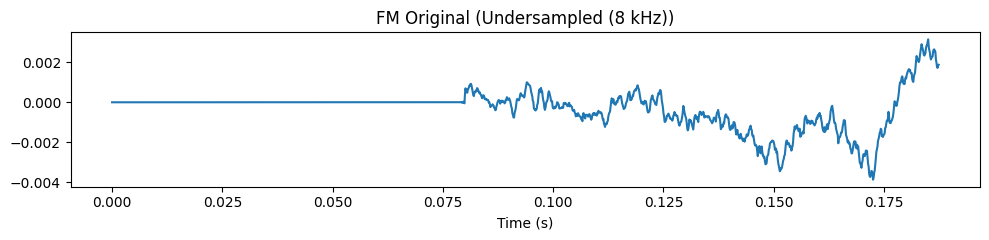

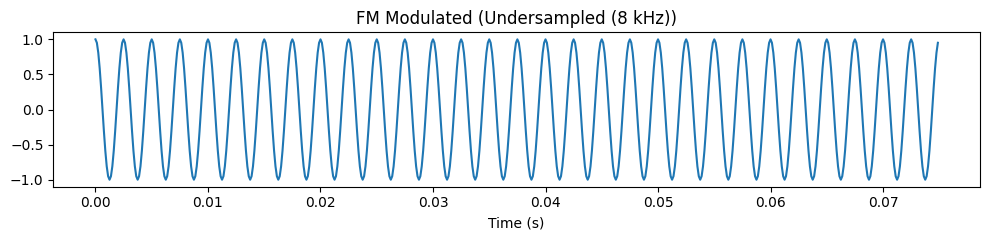

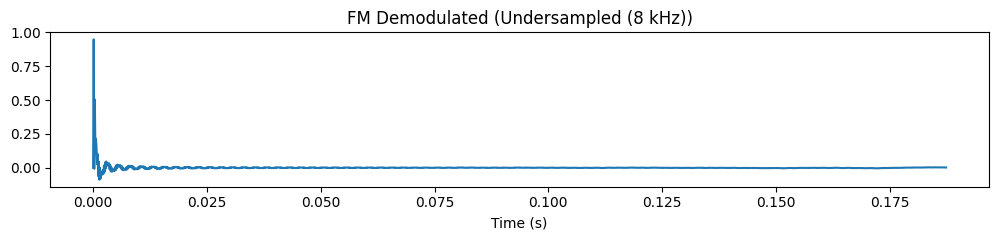

FM Modulated audio:


FM Demodulated audio:



-- Critical (16 kHz) | fs = 16000


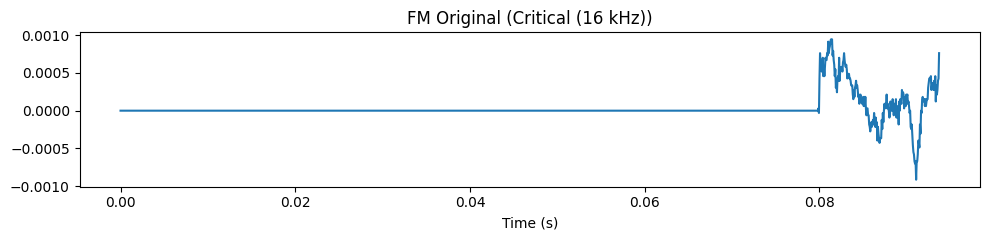

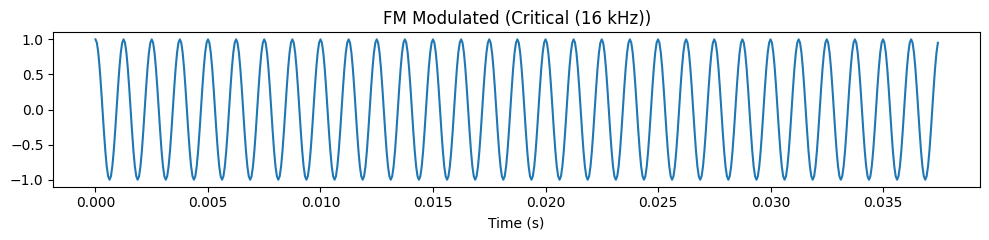

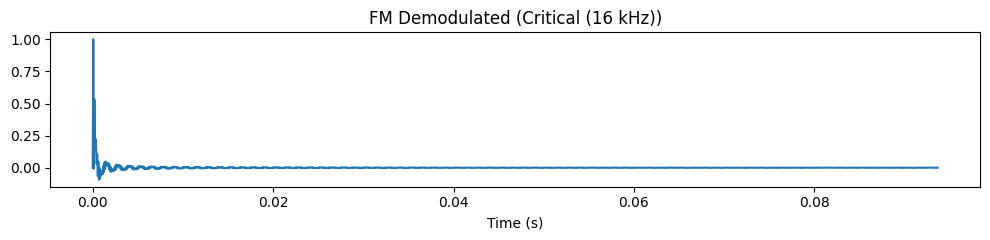

FM Modulated audio:


FM Demodulated audio:



-- Oversampled (32 kHz) | fs = 32000


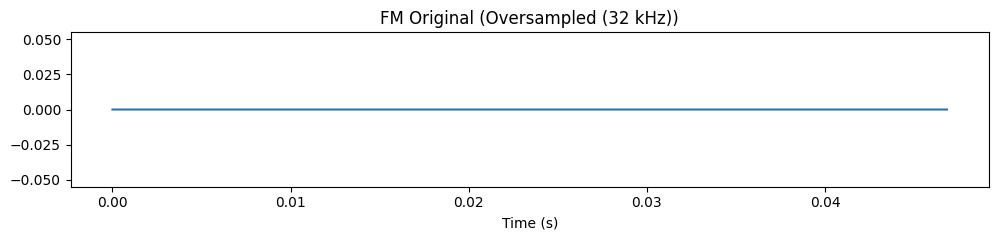

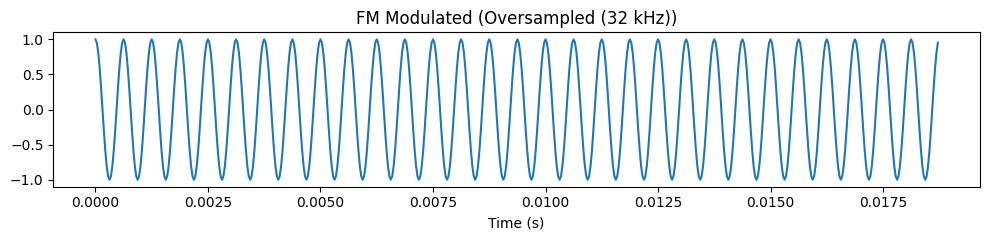

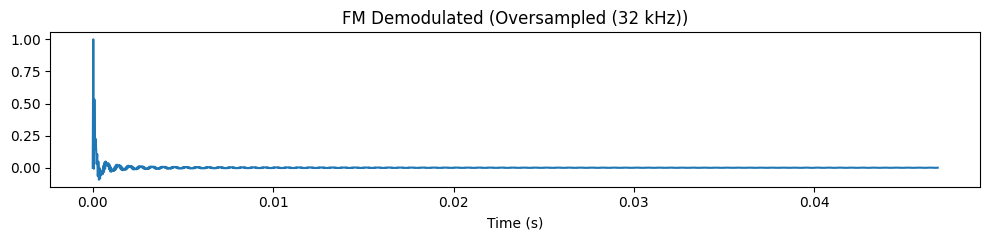

FM Modulated audio:


FM Demodulated audio:


In [ ]:
import numpy as np
from scipy.signal import hilbert, detrend

def fm_modulate(signal, fc, fs, kf):
    t = np.arange(len(signal)) / fs
    int_sig = np.cumsum(signal) / fs
    fm = np.cos(2*np.pi*fc*t + 2*np.pi*kf*int_sig)
    return np.nan_to_num(fm)

def fm_demodulate(fm_signal, fs, kf):
    analytic = hilbert(fm_signal)
    phase = np.unwrap(np.angle(analytic))
    diff = np.diff(phase)
    dem = diff * (fs / (2*np.pi*kf))
    dem = detrend(np.nan_to_num(dem))
    if np.max(np.abs(dem)) > 1e-8:
        dem = dem / np.max(np.abs(dem))
    return np.concatenate(([0], dem))

sampling_cases = {
    "Undersampled (8 kHz)": 8000,
    "Critical (16 kHz)": 16000,
    "Oversampled (32 kHz)": 32000
}

print("=== FM Processing (Improved Visibility) ===")
for label, fs_mod in sampling_cases.items():

    sig = librosa.resample(y=x, orig_sr=sr, target_sr=fs_mod)

    #  Lower carrier frequency for visibility
    fc = int(fs_mod * 0.05)        # 5% of sampling rate

    #  Increase deviation for clearer FM oscillations
    kf = 500

    fm = fm_modulate(sig, fc, fs_mod, kf)
    dem = fm_demodulate(fm, fs_mod, kf)

    print("\n--", label, "| fs =", fs_mod)

    #  Plot fewer samples to zoom into waveform (makes FM visible)
    plot_signal(sig, fs_mod, f"FM Original ({label})", samples=1500)
    plot_signal(fm, fs_mod, f"FM Modulated ({label})", samples=600)  # clear FM view
    plot_signal(dem, fs_mod, f"FM Demodulated ({label})", samples=1500)

    print("FM Modulated audio:")
    play_audio(fm, fs_mod)
    print("FM Demodulated audio:")
    play_audio(dem, fs_mod)


**PCM processing (3 quantization levels) — original, quantized (show levels), reconstructed (plots + audio)**

In [ ]:
# === Extract smooth envelope from real voice for clear PCM visualization ===
import librosa
import numpy as np
from scipy.ndimage import gaussian_filter1d

frame_length = 1024
hop_length = 256

# x is your actual voice signal already loaded
env = librosa.onset.onset_strength(y=x, sr=sr)
env = librosa.util.normalize(env)

# Stretch the envelope to match the length of your voice sample
env = np.interp(np.linspace(0, len(env), len(x)), np.arange(len(env)), env)

# Smooth it for clean step-like PCM display
env_smooth = gaussian_filter1d(env, sigma=50)

print("Smooth envelope extracted for PCM visualization!")


Smooth envelope extracted for PCM visualization!


=== PCM Processing (Improved Visibility + Correct Audio) ===

--- Low (4-bit) (4 bits) ---


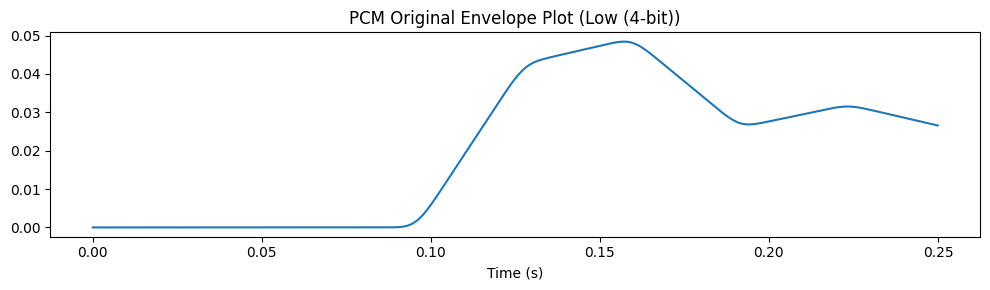

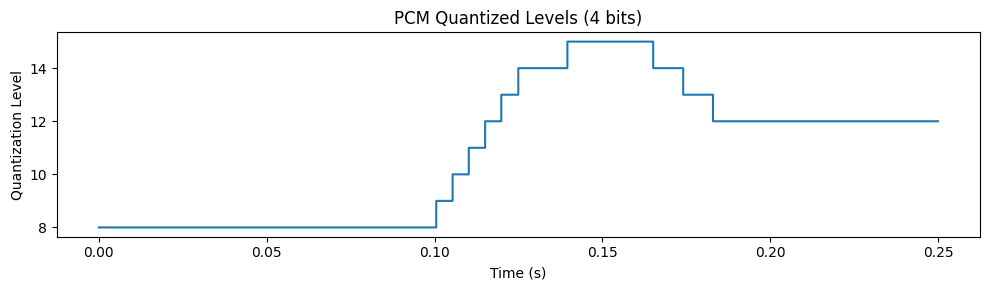

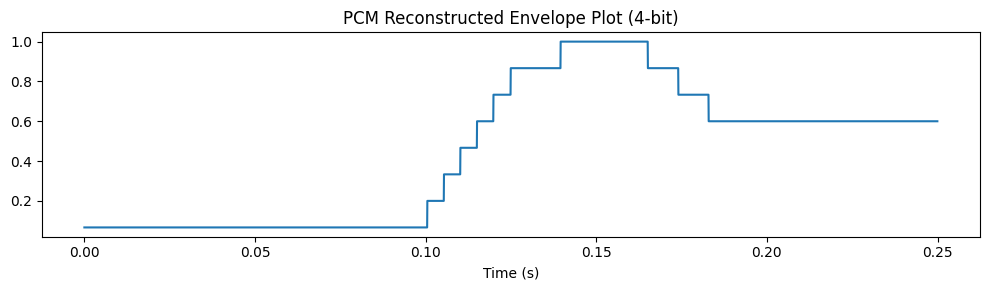

🎧 Playing PCM Quantized Audio:


🎧 Playing PCM Reconstructed Audio:



--- Med (8-bit) (8 bits) ---


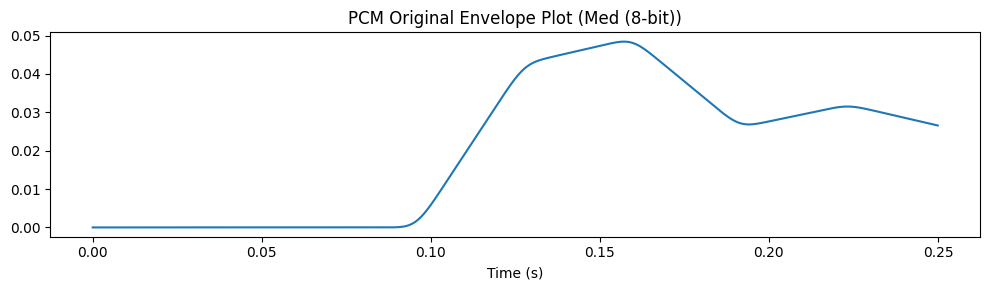

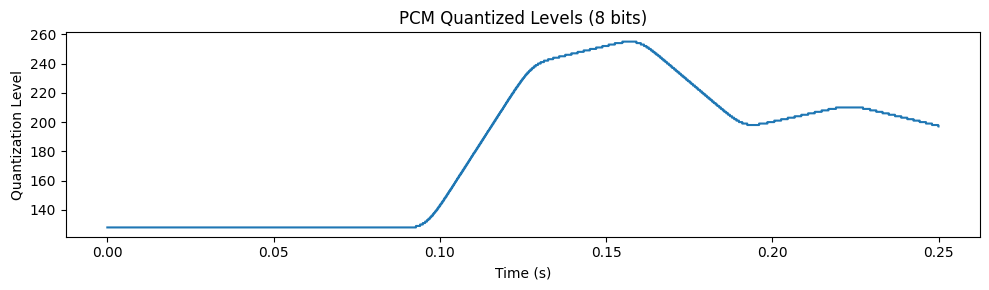

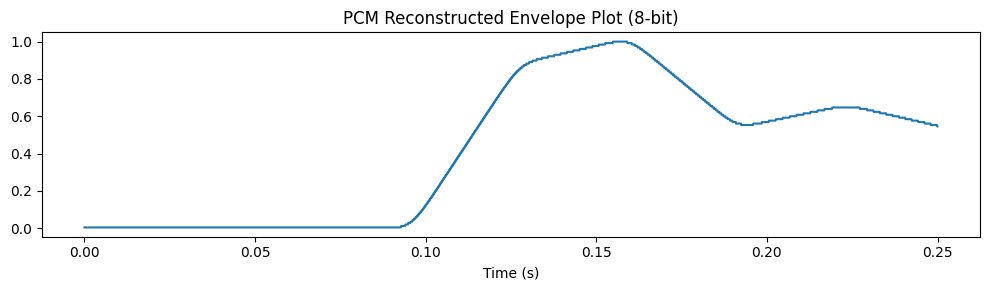

🎧 Playing PCM Quantized Audio:


🎧 Playing PCM Reconstructed Audio:



--- High (16-bit) (16 bits) ---


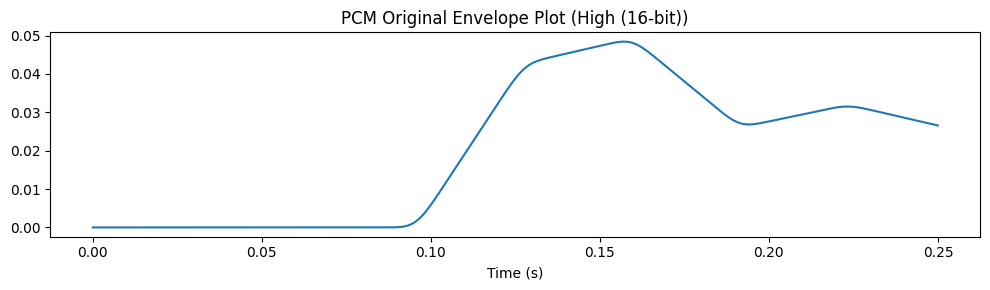

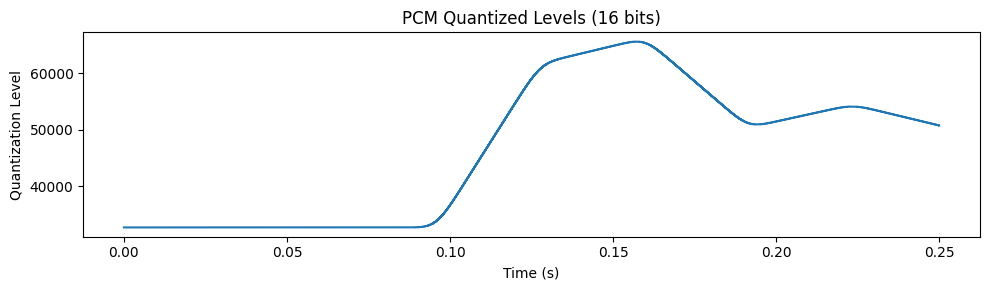

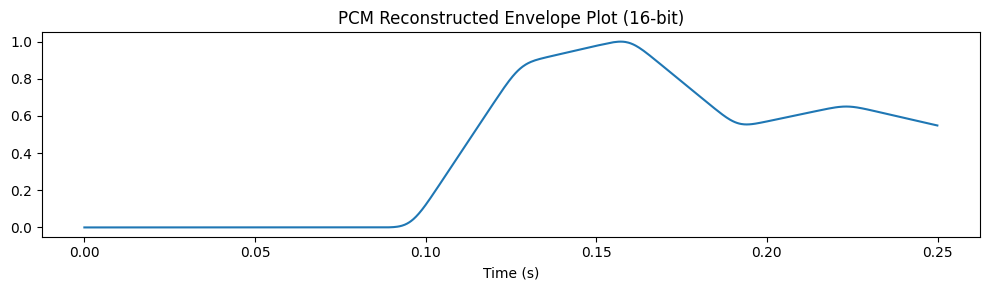

🎧 Playing PCM Quantized Audio:


🎧 Playing PCM Reconstructed Audio:


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def pcm_encode(sig, bits):
    levels = 2**bits
    s = sig / (np.max(np.abs(sig)) + 1e-9)
    q = np.round(((s + 1) / 2) * (levels - 1))
    return q.astype(int)

def pcm_decode(q, bits):
    levels = 2**bits
    return 2 * (q.astype(float) / (levels - 1)) - 1


quant_cases = {
    "Low (4-bit)": 4,
    "Med (8-bit)": 8,
    "High (16-bit)": 16
}

print("=== PCM Processing (Improved Visibility + Correct Audio) ===")

# -----------------------------
# 1) PLOTTING SIGNAL (using smooth envelope)
# -----------------------------
plot_window = env_smooth[:4000]        # 4000 samples → 0.25 sec
tp = np.arange(len(plot_window)) / sr

# -----------------------------
# 2) AUDIO SIGNAL (use actual voice 'x')
# -----------------------------

for label, bits in quant_cases.items():

    # ========== PLOT SECTION ==========
    enc_plot = pcm_encode(plot_window, bits)
    dec_plot = pcm_decode(enc_plot, bits)

    print(f"\n--- {label} ({bits} bits) ---")

    # Original envelope (for plotting ONLY)
    plt.figure(figsize=(10,3))
    plt.plot(tp, plot_window)
    plt.title(f"PCM Original Envelope Plot ({label})")
    plt.xlabel("Time (s)")
    plt.tight_layout()
    plt.show()

    # Quantized steps (textbook PCM)
    plt.figure(figsize=(10,3))
    plt.step(tp, enc_plot, where='post')
    plt.title(f"PCM Quantized Levels ({bits} bits)")
    plt.xlabel("Time (s)")
    plt.ylabel("Quantization Level")
    plt.tight_layout()
    plt.show()

    # Reconstructed envelope
    plt.figure(figsize=(10,3))
    plt.plot(tp, dec_plot)
    plt.title(f"PCM Reconstructed Envelope Plot ({bits}-bit)")
    plt.xlabel("Time (s)")
    plt.tight_layout()
    plt.show()


    # ========== AUDIO SECTION (REAL VOICE) ==========
    # Encode & decode the FULL voice signal x
    enc_audio = pcm_encode(x, bits)
    dec_audio = pcm_decode(enc_audio, bits)

    # Normalize decoded voice
    dec_audio = dec_audio / (np.max(np.abs(dec_audio)) + 1e-9)

    # AUDIO OUTPUTS
    print("🎧 Playing PCM Quantized Audio:")
    enc_audio_norm = (enc_audio - enc_audio.min()) / (enc_audio.max() - enc_audio.min() + 1e-9)
    enc_audio_norm = enc_audio_norm * 2 - 1
    play_audio(enc_audio_norm, sr)

    print("🎧 Playing PCM Reconstructed Audio:")
    play_audio(dec_audio, sr)


**Quality metrics (SNR & MSE) for PCM & FM demodulated**

In [ ]:
import numpy as np

def compute_snr(original, recon):
    L = min(len(original), len(recon))
    orig = original[:L]
    rec = recon[:L]
    noise = orig - rec
    power_signal = np.sum(orig**2) + 1e-12
    power_noise = np.sum(noise**2) + 1e-12
    return 10 * np.log10(power_signal / power_noise)

def compute_mse(original, recon):
    L = min(len(original), len(recon))
    return np.mean((original[:L] - recon[:L])**2)

# PCM metrics (using decoded above)
print("=== PCM Metrics ===")
for label, bits in quant_cases.items():
    enc = pcm_encode(x, bits)
    dec = pcm_decode(enc, bits)
    dec = dec / (np.max(np.abs(dec)) + 1e-9)
    snr = compute_snr(x, dec)
    mse = compute_mse(x, dec)
    print(f"{label} ({bits}-bit): SNR = {snr:.2f} dB, MSE = {mse:.6e}")

# FM metrics: use the FM demodulated signals from Cell 10 (we recompute here)
print("\n=== FM Metrics ===")
for label, fs_mod in sampling_cases.items():
    sig = librosa.resample(y=x, orig_sr=sr, target_sr=fs_mod)
    fc = max(500, int(fs_mod * 0.25))
    kf = 200
    fm = fm_modulate(sig, fc, fs_mod, kf)
    dem = fm_demodulate(fm, fs_mod, kf)
    # resample dem back to original sr for fair comparison
    dem_up = librosa.resample(y=dem, orig_sr=fs_mod, target_sr=sr)
    snr = compute_snr(x, dem_up)
    mse = compute_mse(x, dem_up)
    print(f"{label} ({fs_mod} Hz): SNR = {snr:.2f} dB, MSE = {mse:.6e}")


=== PCM Metrics ===
Low (4-bit) (4-bit): SNR = 2.38 dB, MSE = 3.121649e-03
Med (8-bit) (8-bit): SNR = 17.00 dB, MSE = 1.077945e-04
High (16-bit) (16-bit): SNR = 17.29 dB, MSE = 1.008844e-04

=== FM Metrics ===
Undersampled (8 kHz) (8000 Hz): SNR = 5.38 dB, MSE = 1.563289e-03
Critical (16 kHz) (16000 Hz): SNR = 2.65 dB, MSE = 2.936565e-03
Oversampled (32 kHz) (32000 Hz): SNR = 1.66 dB, MSE = 3.689287e-03


**Save some outputs to drive**

In [ ]:
out_dir = "/content/drive/MyDrive/DC_Project_outputs"
import os
os.makedirs(out_dir, exist_ok=True)

# Save PCM 16-bit reconstructed
enc = pcm_encode(x, 16)
dec = pcm_decode(enc, 16)
dec = dec / (np.max(np.abs(dec)) + 1e-9)
import soundfile as sf
sf.write(os.path.join(out_dir, "pcm_16_reconstructed.wav"), dec, sr)

# Save FM critical demodulated
fs_mod = 16000
fc = max(500, int(fs_mod * 0.25))
kf = 200
sig = librosa.resample(y=x, orig_sr=sr, target_sr=fs_mod)
fm = fm_modulate(sig, fc, fs_mod, kf)
dem = fm_demodulate(fm, fs_mod, kf)
dem_up = librosa.resample(y=dem, orig_sr=fs_mod, target_sr=sr)
sf.write(os.path.join(out_dir, "fm_critical_demodulated.wav"), dem_up, sr)

print("Saved example outputs to", out_dir)


Saved example outputs to /content/drive/MyDrive/DC_Project_outputs
